# Data Visualization with t-SNE

This notebook implements the Data Visualization section of the project. The goal is to project the high-dimensional Student Dropout dataset into 2D and 3D using t-SNE, then inspect whether the target classes show visible local structure.

Important interpretation rule: t-SNE is mainly for local-neighborhood visualization. Cluster sizes and long-range distances between clusters should be interpreted cautiously.

## 1. Import Packages

In [8]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.manifold import TSNE, trustworthiness
from sklearn.metrics import davies_bouldin_score, silhouette_score
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import OneHotEncoder, StandardScaler

plt.rcParams["figure.dpi"] = 120
plt.rcParams["font.family"] = "DejaVu Sans"
sns.set_theme(style="whitegrid", context="notebook")

RANDOM_STATE = 42
print("Libraries loaded successfully.")

Libraries loaded successfully.


## 2. Load Processed Data

The preprocessed dataset has numeric features and an encoded target column. The target mapping from preprocessing is:

- `0`: Dropout
- `1`: Enrolled
- `2`: Graduate

In [9]:
DATA_PATH = Path("dataset/processed_data.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("../dataset/processed_data.csv")

df = pd.read_csv(DATA_PATH)
df.columns = df.columns.str.strip()

target_map = {
    0: "Dropout",
    1: "Enrolled",
    2: "Graduate",
}

df["Target"] = df["Target"].astype(int)
df["Target Label"] = df["Target"].map(target_map)

print(f"Dataset shape: {df.shape}")
print("Target distribution:")
display(df["Target Label"].value_counts().rename_axis("Target").to_frame("Count"))
display(df.head())

Dataset shape: (4424, 38)
Target distribution:


,Count
Target,
Graduate,2209
Dropout,1421
Enrolled,794


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target,Target Label
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0.000000,0,10.8,1.4,1.74,0,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,6,6,6,13.666667,0,13.9,-0.3,0.79,2,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,6,0,0,0.000000,0,10.8,1.4,1.74,0,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,6,10,5,12.400000,0,9.4,-0.8,-3.12,2,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,6,6,6,13.000000,0,13.9,-0.3,0.79,2,Graduate


## 3. Prepare Features for t-SNE

`Target` is excluded from the input features and used only for coloring the plots. The dataset contains both encoded categorical variables and continuous numeric variables. For a more rigorous distance-based visualization, categorical variables are one-hot encoded while continuous and ordinal numeric variables are standardized.

In [10]:
feature_cols = [col for col in df.columns if col not in ["Target", "Target Label"]]
X = df[feature_cols].copy()
y = df["Target"].copy()
y_label = df["Target Label"].copy()

# These columns are integer-coded categories in the original dataset, not continuous quantities.
categorical_feature_cols = [
    "Marital status",
    "Application mode",
    "Course",
    "Daytime/evening attendance",
    "Previous qualification",
    "Nacionality",
    "Mother's qualification",
    "Father's qualification",
    "Mother's occupation",
    "Father's occupation",
    "Displaced",
    "Educational special needs",
    "Debtor",
    "Tuition fees up to date",
    "Gender",
    "Scholarship holder",
    "International",
]
categorical_feature_cols = [col for col in categorical_feature_cols if col in X.columns]
numeric_feature_cols = [col for col in X.columns if col not in categorical_feature_cols]

preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_feature_cols),
        ("numeric", StandardScaler(), numeric_feature_cols),
    ],
    verbose_feature_names_out=False,
)

X_prepared = preprocessor.fit_transform(X)

print(f"Number of samples: {X_prepared.shape[0]}")
print(f"Original input features before encoding: {len(feature_cols)}")
print(f"t-SNE input features after one-hot encoding and scaling: {X_prepared.shape[1]}")
print("Categorical features one-hot encoded:", len(categorical_feature_cols))
print("Numeric/ordinal features standardized:", len(numeric_feature_cols))
print("Target excluded from feature matrix:", "Target" not in feature_cols)

Number of samples: 4424
Original input features before encoding: 36
t-SNE input features after one-hot encoding and scaling: 255
Categorical features one-hot encoded: 17
Numeric/ordinal features standardized: 19
Target excluded from feature matrix: True


## 4. Helper Plotting Functions

In [11]:
palette = {
    "Dropout": "#d55e00",
    "Enrolled": "#0072b2",
    "Graduate": "#009e73",
}

def make_tsne(n_components=2, perplexity=30):
    model = TSNE(
        n_components=n_components,
        perplexity=perplexity,
        learning_rate="auto",
        init="pca",
        random_state=RANDOM_STATE,
    )
    return model.fit_transform(X_prepared)

def embedding_frame(embedding, prefix="TSNE"):
    data = pd.DataFrame(embedding, columns=[f"{prefix}{i + 1}" for i in range(embedding.shape[1])])
    data["Target"] = y.values
    data["Target Label"] = y_label.values
    return data

def plot_tsne_2d(data, title, ax=None, legend=True):
    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 6))
    sns.scatterplot(
        data=data,
        x="TSNE1",
        y="TSNE2",
        hue="Target Label",
        hue_order=["Dropout", "Enrolled", "Graduate"],
        palette=palette,
        s=18,
        alpha=0.75,
        linewidth=0,
        ax=ax,
        legend=legend,
    )
    ax.set_title(title)
    ax.set_xlabel("t-SNE dimension 1")
    ax.set_ylabel("t-SNE dimension 2")
    if legend:
        ax.legend(title="Target", loc="best", frameon=True)
    return ax

def knn_label_agreement(points, labels, n_neighbors=15):
    neighbors = NearestNeighbors(n_neighbors=n_neighbors + 1).fit(points)
    neighbor_indices = neighbors.kneighbors(return_distance=False)[:, 1:]
    return (labels[neighbor_indices] == labels[:, None]).mean()

def random_same_label_baseline(labels):
    proportions = pd.Series(labels).value_counts(normalize=True)
    return float((proportions ** 2).sum())

def evaluate_embedding(name, embedding, n_neighbors=15):
    labels = y.to_numpy()
    return {
        "Embedding": name,
        "Dimensions": embedding.shape[1],
        "Silhouette by Target": silhouette_score(embedding, labels),
        "Davies-Bouldin by Target": davies_bouldin_score(embedding, labels),
        f"Trustworthiness@{n_neighbors}": trustworthiness(X_prepared, embedding, n_neighbors=n_neighbors),
        f"KNN Label Agreement@{n_neighbors}": knn_label_agreement(embedding, labels, n_neighbors=n_neighbors),
    }

## 5. Main 2D t-SNE Projection

`perplexity=30` is used as the main setting because it balances local and broader neighborhood structure for a dataset of this size.

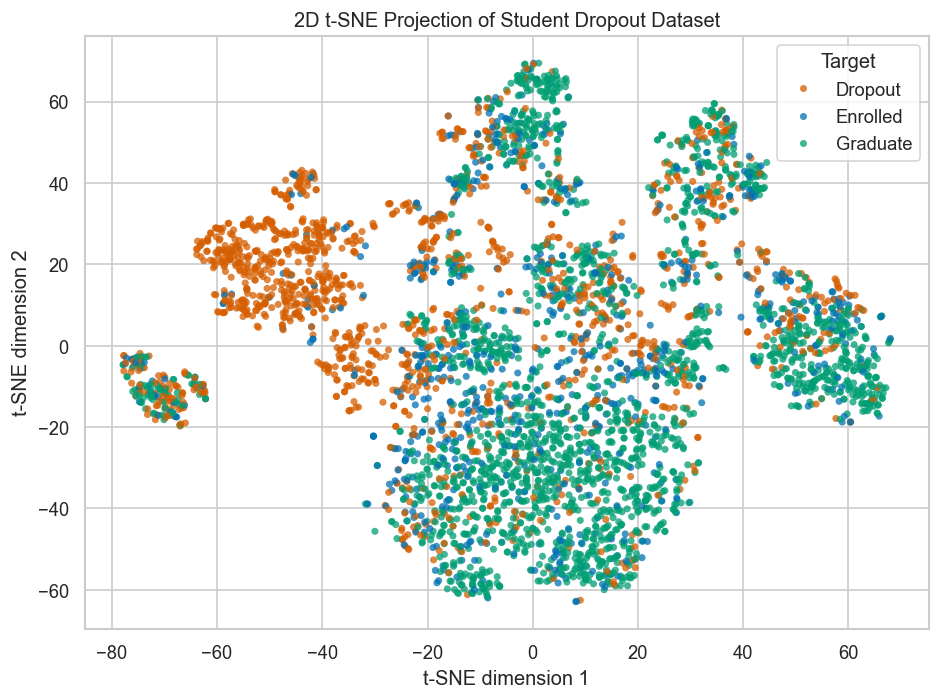

,TSNE1,TSNE2,Target,Target Label
0,-66.330284,-15.248606,0,Dropout
1,17.138304,-25.326008,2,Graduate
2,-61.820347,25.936541,0,Dropout
3,-5.099010,53.054626,2,Graduate
4,7.804188,21.547667,2,Graduate


In [12]:
tsne_2d = make_tsne(n_components=2, perplexity=30)
tsne_2d_df = embedding_frame(tsne_2d)

fig, ax = plt.subplots(figsize=(8, 6))
plot_tsne_2d(tsne_2d_df, "2D t-SNE Projection of Student Dropout Dataset", ax=ax)
plt.tight_layout()
plt.show()

display(tsne_2d_df.head())

## 6. 3D t-SNE Projection

The 3D view provides an additional perspective on local class separation. It should be used as supporting evidence rather than a replacement for quantitative model evaluation.

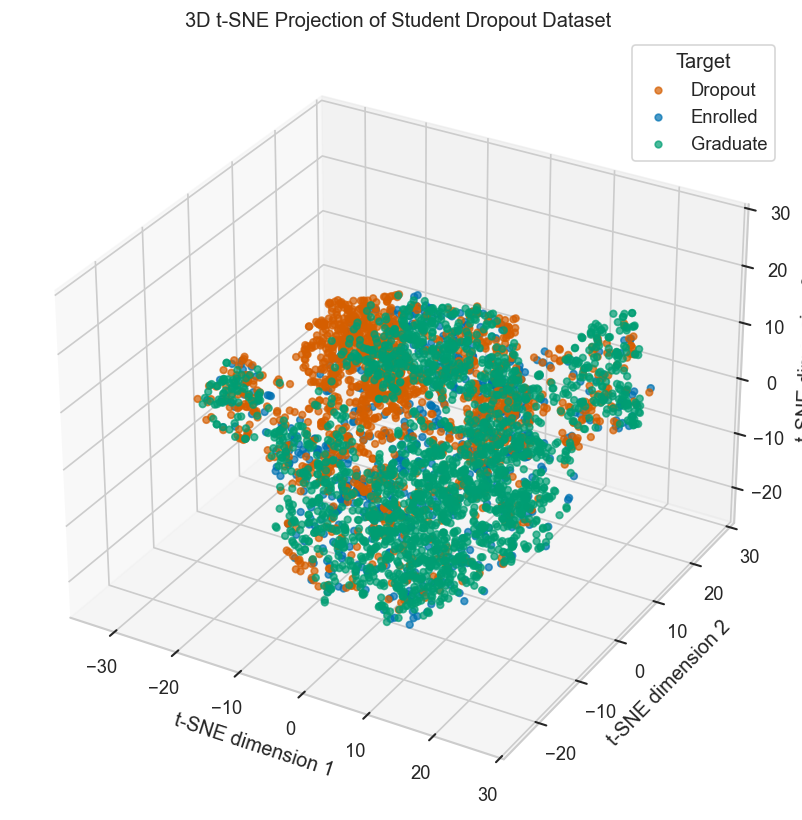

In [13]:
tsne_3d = make_tsne(n_components=3, perplexity=30)
tsne_3d_df = embedding_frame(tsne_3d)

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")

for label in ["Dropout", "Enrolled", "Graduate"]:
    subset = tsne_3d_df[tsne_3d_df["Target Label"] == label]
    ax.scatter(
        subset["TSNE1"],
        subset["TSNE2"],
        subset["TSNE3"],
        label=label,
        s=16,
        alpha=0.7,
        color=palette[label],
    )

ax.set_title("3D t-SNE Projection of Student Dropout Dataset")
ax.set_xlabel("t-SNE dimension 1")
ax.set_ylabel("t-SNE dimension 2")
ax.set_zlabel("t-SNE dimension 3")
ax.legend(title="Target", loc="best")
plt.tight_layout()
plt.show()

## 7. Perplexity Sensitivity Analysis

Perplexity controls the effective number of neighbors used by t-SNE. Lower values emphasize very local structure; higher values incorporate broader neighborhood information. The visual pattern should be checked under multiple settings before drawing conclusions.

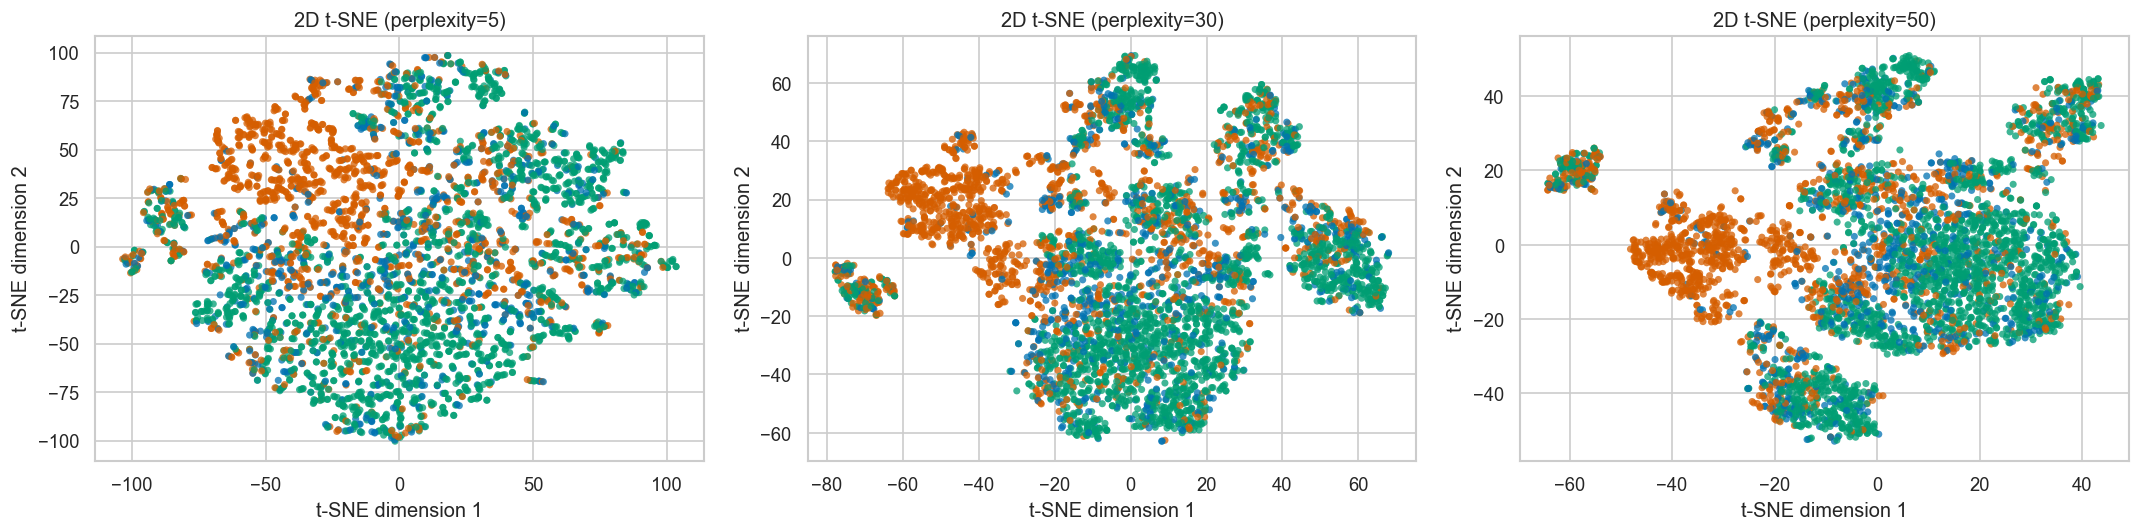

In [14]:
perplexities = [5, 30, 50]
tsne_embeddings_2d = {30: tsne_2d}

fig, axes = plt.subplots(1, len(perplexities), figsize=(18, 5), sharex=False, sharey=False)

for ax, perplexity in zip(axes, perplexities):
    if perplexity not in tsne_embeddings_2d:
        tsne_embeddings_2d[perplexity] = make_tsne(n_components=2, perplexity=perplexity)
    embedding = tsne_embeddings_2d[perplexity]
    data = embedding_frame(embedding)
    plot_tsne_2d(
        data,
        title=f"2D t-SNE (perplexity={perplexity})",
        ax=ax,
        legend=False,
    )

handles, labels = axes[-1].get_legend_handles_labels()
if handles:
    fig.legend(handles, labels, title="Target", loc="upper center", ncol=3, frameon=True)

plt.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()

## 8. Auxiliary Quality Metrics

These metrics do not replace visual inspection, but they make the interpretation more rigorous.

- `Trustworthiness`: how well local neighborhoods from the high-dimensional data are preserved in the embedding. Higher is better.
- `Silhouette by Target`: how separated the target classes are in the embedding. Values near 0 indicate overlapping classes.
- `Davies-Bouldin by Target`: another class-separation metric. Lower is better.
- `KNN Label Agreement`: the fraction of nearest neighbors in the embedding that share the same target label. Compare it with the random same-label baseline.


In [8]:
N_NEIGHBORS = 15
metrics_rows = []

for perplexity in perplexities:
    metrics_rows.append(
        evaluate_embedding(
            name=f"2D t-SNE perplexity={perplexity}",
            embedding=tsne_embeddings_2d[perplexity],
            n_neighbors=N_NEIGHBORS,
        )
    )

metrics_rows.append(
    evaluate_embedding(
        name="3D t-SNE perplexity=30",
        embedding=tsne_3d,
        n_neighbors=N_NEIGHBORS,
    )
)

metrics_df = pd.DataFrame(metrics_rows)

baseline_df = pd.DataFrame(
    {
        "Metric": [
            f"Prepared-space KNN Label Agreement@{N_NEIGHBORS}",
            "Random Same-Label Baseline",
        ],
        "Value": [
            knn_label_agreement(X_prepared, y.to_numpy(), n_neighbors=N_NEIGHBORS),
            random_same_label_baseline(y.to_numpy()),
        ],
    }
)

display(metrics_df.round(4))
display(baseline_df.round(4))

,Embedding,Dimensions,Silhouette by Target,Davies-Bouldin by Target,Trustworthiness@15,KNN Label Agreement@15
0,2D t-SNE perplexity=5,2,0.0029,6.8985,0.9566,0.5780
1,2D t-SNE perplexity=30,2,0.0157,5.9721,0.9714,0.5844
2,2D t-SNE perplexity=50,2,0.0222,5.5304,0.9730,0.5919
3,3D t-SNE perplexity=30,3,0.0234,6.2471,0.9789,0.5928


,Metric,Value
0,Prepared-space KNN Label Agreement@15,0.6174
1,Random Same-Label Baseline,0.3847


## 9. Discussion

The t-SNE visualization should be interpreted as a local-neighborhood map of students with similar enrollment, demographic, socioeconomic, and semester-performance characteristics. If `Graduate` points form visibly dense regions, this suggests that successful students share similar feature profiles in the prepared input space. If `Dropout` and `Enrolled` points overlap with other classes, this indicates that their profiles are less cleanly separated by visualization alone and may require supervised models or additional feature engineering for stronger discrimination.

The auxiliary metrics should be interpreted together with the plots. High trustworthiness supports that the embedding preserves local neighborhoods. However, near-zero silhouette scores or high Davies-Bouldin scores would indicate that the target classes are still substantially overlapping in the t-SNE space. The perplexity comparison is part of the interpretation. Stable class patterns across `perplexity=5`, `30`, and `50` are more credible than patterns that appear only under one setting. Following the lecture guidance, cluster sizes and long-range distances between clusters should not be treated as direct evidence of class frequency or between-class dissimilarity.